In [34]:
import pandas as pd
import numpy as np

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
from scipy import stats

In [36]:
ab_data = pd.read_csv("ab_data.csv")
countries = pd.read_csv("countries.csv")

In [37]:
print("AB Data Shape : ", ab_data.shape)
print("Countries Data Shape : ", countries.shape)

AB Data Shape :  (294478, 5)
Countries Data Shape :  (290584, 2)


In [38]:
print("A/B Test Data : ")
display(ab_data.head())

A/B Test Data : 


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [39]:
print("\nCountries Data : ")
display(countries.head())


Countries Data : 


,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


In [40]:
print("A/B Test Columns : ")
print(ab_data.columns)

A/B Test Columns : 
Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted'], dtype='str')


In [41]:
print("Countries Test Columns : ")
print(countries.columns)

Countries Test Columns : 
Index(['user_id', 'country'], dtype='str')


In [42]:
ab_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 11.2 MB


In [43]:
countries.info()

<class 'pandas.DataFrame'>
RangeIndex: 290584 entries, 0 to 290583
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype
---  ------   --------------   -----
 0   user_id  290584 non-null  int64
 1   country  290584 non-null  str  
dtypes: int64(1), str(1)
memory usage: 4.4 MB


In [44]:
print("Missing values in A/B data : ")
print(ab_data.isnull().sum())

Missing values in A/B data : 
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64


In [45]:
print("Missing values in Countries data : ")
print(countries.isnull().sum())

Missing values in Countries data : 
user_id    0
country    0
dtype: int64


In [46]:
print(ab_data['group'].value_counts())

group
treatment    147276
control      147202
Name: count, dtype: int64


In [47]:
print(ab_data['landing_page'].value_counts())

landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64


In [48]:
print(ab_data['converted'].value_counts())

converted
0    259241
1     35237
Name: count, dtype: int64


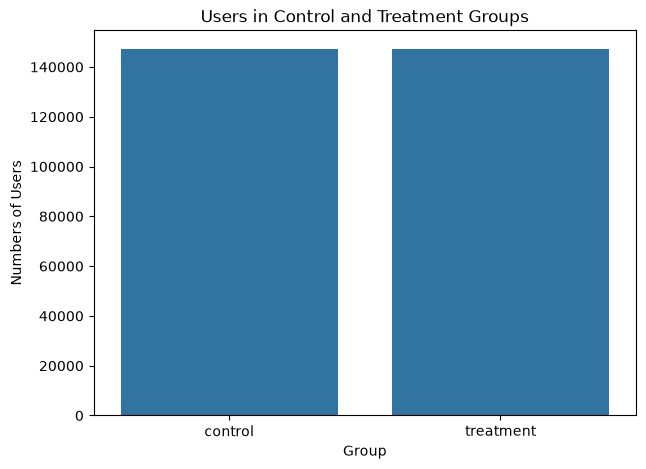

In [51]:
plt.figure(figsize = (7,5))
sns.countplot(
    data = ab_data, 
    x = 'group'
)

plt.title("Users in Control and Treatment Groups")
plt.xlabel("Group")
plt.ylabel("Numbers of Users")
plt.show()

In [53]:
clean_data = ab_data[
    ((ab_data['group'] == 'control') &
    (ab_data['landing_page'] == 'old_page'))
    |
    ((ab_data['group'] == 'treatment') &
    (ab_data['landing_page'] == 'new_page'))
].copy()

print("Data after removing mismatched records : ")
print(clean_data.shape)

Data after removing mismatched records : 
(290585, 5)


In [55]:
duplicate_count = clean_data['user_id'].duplicated().sum()
print("Number of duplicate users : ", duplicate_count)

Number of duplicate users :  1


In [57]:
clean_data = clean_data.drop_duplicates(
    subset = 'user_id',
    keep = 'first'
)
print("data after removing duplicate users : ")
print(clean_data.shape)

data after removing duplicate users : 
(290584, 5)


In [59]:
data = pd.merge(
    clean_data,
    countries,
    on = "user_id",
    how = "inner"
)

print("Final dataset shape : ")
print(data.shape)
display(data.head())

Final dataset shape : 
(290584, 6)


,user_id,timestamp,group,landing_page,converted,country
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,US
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,US
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,US
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,US
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,US


In [61]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 290584 entries, 0 to 290583
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       290584 non-null  int64
 1   timestamp     290584 non-null  str  
 2   group         290584 non-null  str  
 3   landing_page  290584 non-null  str  
 4   converted     290584 non-null  int64
 5   country       290584 non-null  str  
dtypes: int64(2), str(4)
memory usage: 13.3 MB


In [63]:
print(data.isnull().sum())

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
country         0
dtype: int64


In [66]:
print(data['group'].value_counts())

group
treatment    145310
control      145274
Name: count, dtype: int64


In [68]:
conversions_summary = data.groupby('group')['converted'].agg(
    ['count', 'sum', 'mean']
)

conversions_summary.columns = [
    'Users', 
    'Conversions',
    'Conversion_Rate'
]

conversions_summary['Conversion_Rate_%'] = (
    conversions_summary['Conversion_Rate'] * 100
)

display(conversions_summary)

,Users,Conversions,Conversion_Rate,Conversion_Rate_%
group,,,,
control,145274,17489,0.120386,12.038630
treatment,145310,17264,0.118808,11.880807


In [70]:
control_rate = data[
    data['group'] == 'control'
]['converted'].mean()

treatment_rate = data[
    data['group'] == 'treatment'
]['converted'].mean()

difference = treatment_rate - control_rate
print("Control Conversion Rate : ", round(control_rate * 100, 3), "%")
print("Treatment Conversion Rate :", round(treatment_rate * 100, 3), "%")
print("Difference                :", round(difference * 100, 3), "percentage points")

Control Conversion Rate :  12.039 %
Treatment Conversion Rate : 11.881 %
Difference                : -0.158 percentage points


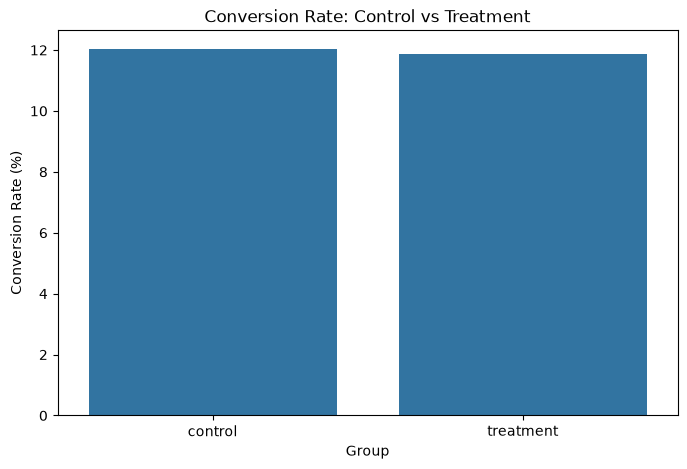

In [73]:
conversion_rates = (
    data.groupby('group')['converted']
    .mean()
    .reset_index()
)

conversion_rates['converted'] = (
    conversion_rates['converted'] * 100
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=conversion_rates,
    x='group',
    y='converted'
)

plt.title("Conversion Rate: Control vs Treatment")
plt.xlabel("Group")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [76]:
alpha = 0.05
print("Significance Level = ", alpha)

Significance Level =  0.05


In [80]:
control = data[
    data['group'] == 'control'
]['converted']

treatment = data[
    data['group'] == 'treatment'
]['converted']

t_stat, p_value_ttest = stats.ttest_ind(
    treatment,
    control,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value_ttest)

T-statistic: -1.310922637465592
P-value: 0.18988493791578315


In [83]:
if p_value_ttest < alpha:
    print("Reject H0")
    print("There is a statistically significant difference.")
else:
    print("Fail to Reject H0")
    print("There is no statistically significant difference.")

Fail to Reject H0
There is no statistically significant difference.


In [85]:
contingency_table = pd.crosstab(
    data['group'],
    data['converted']
)

print(contingency_table)

converted       0      1
group                   
control    127785  17489
treatment  128046  17264


In [87]:
chi2, p_value_chi, degrees_of_freedom, expected = (
    stats.chi2_contingency(contingency_table)
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", p_value_chi)

Chi-square statistic: 1.7035660051885058
Degrees of freedom: 1
P-value: 0.19182228096235662


In [89]:
if p_value_chi < alpha:
    print("Reject H0")
    print("There is a significant relationship between group and conversion.")
else:
    print("Fail to Reject H0")
    print("There is no statistically significant relationship between group and conversion.")

Fail to Reject H0
There is no statistically significant relationship between group and conversion.


In [91]:
country_summary = data.groupby('country')['converted'].agg(
    ['count', 'sum', 'mean']
)

country_summary.columns = [
    'Users',
    'Conversions',
    'Conversion_Rate'
]

country_summary['Conversion_Rate_%'] = (
    country_summary['Conversion_Rate'] * 100
)

display(country_summary)

,Users,Conversions,Conversion_Rate,Conversion_Rate_%
country,,,,
CA,14499,1672,0.115318,11.531830
UK,72466,8739,0.120594,12.059449
US,203619,24342,0.119547,11.954680


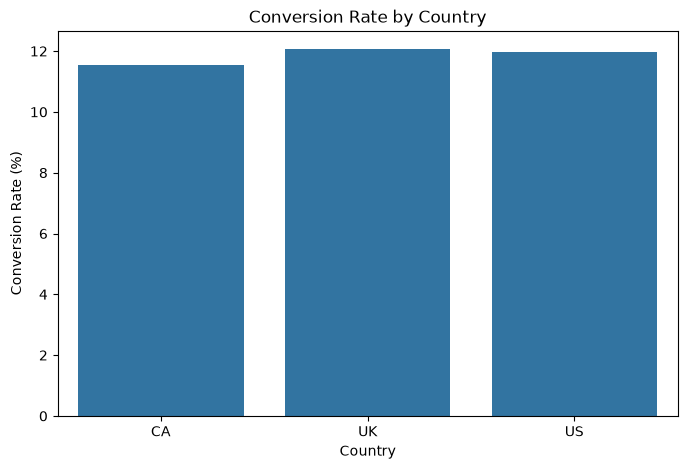

In [94]:
country_rates = (
    data.groupby('country')['converted']
    .mean()
    .reset_index()
)

country_rates['converted'] *= 100

plt.figure(figsize=(8,5))

sns.barplot(
    data=country_rates,
    x='country',
    y='converted'
)

plt.title("Conversion Rate by Country")
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [96]:
country_groups = []

for country, group in data.groupby('country'):
    country_groups.append(
        group['converted'].values
    )

f_stat_country, p_value_country = stats.f_oneway(
    *country_groups
)

print("F-statistic:", f_stat_country)
print("P-value:", p_value_country)

F-statistic: 1.6052863959236423
P-value: 0.20083381022160934


In [98]:
if p_value_country < alpha:
    print("Reject H0")
    print("There is a significant difference between countries.")
else:
    print("Fail to Reject H0")
    print("There is no statistically significant difference between countries.")

Fail to Reject H0
There is no statistically significant difference between countries.


In [100]:
data['country_strategy'] = (
    data['country'] + "_" + data['group']
)

print(data['country_strategy'].value_counts())

country_strategy
US_treatment    101903
US_control      101716
UK_control       36360
UK_treatment     36106
CA_treatment      7301
CA_control        7198
Name: count, dtype: int64


In [102]:
country_strategy_groups = []

for name, group in data.groupby('country_strategy'):
    country_strategy_groups.append(
        group['converted'].values
    )

f_stat_cs, p_value_cs = stats.f_oneway(
    *country_strategy_groups
)

print("F-statistic:", f_stat_cs)
print("P-value:", p_value_cs)

F-statistic: 1.4664379009534279
P-value: 0.1970874768357987


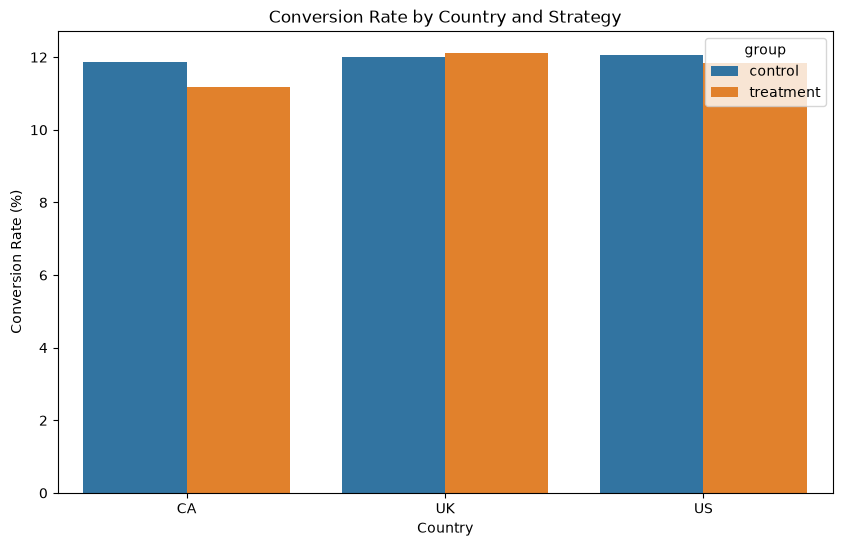

In [104]:
country_strategy_summary = (
    data.groupby(
        ['country', 'group']
    )['converted']
    .mean()
    .reset_index()
)

country_strategy_summary['converted'] *= 100

plt.figure(figsize=(10,6))

sns.barplot(
    data=country_strategy_summary,
    x='country',
    y='converted',
    hue='group'
)

plt.title("Conversion Rate by Country and Strategy")
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [105]:
def confidence_interval(conversions, total, confidence=0.95):
    
    proportion = conversions / total
    
    z = stats.norm.ppf(
        1 - (1 - confidence) / 2
    )
    
    standard_error = np.sqrt(
        proportion * (1 - proportion) / total
    )
    
    margin = z * standard_error
    
    lower = proportion - margin
    upper = proportion + margin
    
    return lower, upper

In [107]:
control_conversions = data[
    data['group'] == 'control'
]['converted'].sum()

control_total = data[
    data['group'] == 'control'
].shape[0]

control_lower, control_upper = confidence_interval(
    control_conversions,
    control_total
)

print("Control Conversion Rate:",
      control_conversions / control_total)

print("95% CI:",
      control_lower,
      control_upper)

Control Conversion Rate: 0.1203863045004612
95% CI: 0.11871294722381814 0.12205966177710426


In [109]:
treatment_conversions = data[
    data['group'] == 'treatment'
]['converted'].sum()

treatment_total = data[
    data['group'] == 'treatment'
].shape[0]

treatment_lower, treatment_upper = confidence_interval(
    treatment_conversions,
    treatment_total
)

print("Treatment Conversion Rate:",
      treatment_conversions / treatment_total)

print("95% CI:",
      treatment_lower,
      treatment_upper)

Treatment Conversion Rate: 0.11880806551510564
95% CI: 0.11714442856134422 0.12047170246886707


In [110]:
results = pd.DataFrame({
    'Statistical Test': [
        'Welch T-Test',
        'Chi-Square Test',
        'ANOVA - Country',
        'ANOVA - Country + Strategy'
    ],
    
    'Test Statistic': [
        t_stat,
        chi2,
        f_stat_country,
        f_stat_cs
    ],
    
    'P-Value': [
        p_value_ttest,
        p_value_chi,
        p_value_country,
        p_value_cs
    ]
})

results['Decision'] = np.where(
    results['P-Value'] < alpha,
    'Reject H0',
    'Fail to Reject H0'
)

display(results)

,Statistical Test,Test Statistic,P-Value,Decision
0,Welch T-Test,-1.310923,0.189885,Fail to Reject H0
1,Chi-Square Test,1.703566,0.191822,Fail to Reject H0
2,ANOVA - Country,1.605286,0.200834,Fail to Reject H0
3,ANOVA - Country + Strategy,1.466438,0.197087,Fail to Reject H0
